### récuperation des catégories emotions

In [1]:
with open("/home/aguerouani/free-gen-playlist/Data/archive/dataset/categories.txt", "r", encoding="utf-8") as f:
    # Lire toutes les lignes, enlever les sauts de ligne
    genres = [line.strip() for line in f]

# Vérification
print(genres[:20])  # Affiche les 20 premiers pour vérifier
print(f"Nombre total de genres : {len(genres)}")

['Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous', 'Boisterous']
Nombre total de genres : 903


### Embedding extraction

In [14]:
import torch
import librosa
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
from muq import MuQ


In [7]:
from embedding_extraction import extract_embedding
data_dir = 'Data/archive/dataset/Audio'
embeddings = []
filenames = []


files = [f for f in os.listdir(data_dir) if f.endswith(".mp3")]

# Trier correctement par numéro
files_sorted = sorted(files, key=lambda x: int(x.split(".")[0]))

i=0
for file in files_sorted:
    file_path = os.path.join(data_dir ,file)
    emb = extract_embedding(file_path)
    if emb is None:
        continue
    embeddings.append(emb)
    filenames.append(file)
    # 🔹 LOG après chaque audio traité
    print(f"✅ Fichier traité : {file} | Genre : {genres[i]} | Embedding : {emb.shape}")


# --- 5. Sauvegarde ---
embeddings = np.array(embeddings)
df = pd.DataFrame(embeddings) 
df['genre'] = genres
df['filename'] = filenames

# En CSV (lisible avec pandas) :
df.to_csv("muq_embedding_MIREX.csv", index=False)

# Ou en format PyTorch pour entraînement direct :
torch.save({'embeddings': torch.tensor(embeddings), 'genres': genres, 'filenames': filenames}, "muq_embeddings.pt")

print("✅ Extraction terminée !")
print("Dimensions embeddings :", embeddings.shape)  # (N, D)


✅ Fichier traité : 001.mp3 | Genre : Boisterous | Embedding : (1024,)
✅ Fichier traité : 002.mp3 | Genre : Boisterous | Embedding : (1024,)
✅ Fichier traité : 003.mp3 | Genre : Boisterous | Embedding : (1024,)
✅ Fichier traité : 004.mp3 | Genre : Boisterous | Embedding : (1024,)
✅ Fichier traité : 005.mp3 | Genre : Boisterous | Embedding : (1024,)
✅ Fichier traité : 006.mp3 | Genre : Boisterous | Embedding : (1024,)
✅ Fichier traité : 007.mp3 | Genre : Boisterous | Embedding : (1024,)
✅ Fichier traité : 008.mp3 | Genre : Boisterous | Embedding : (1024,)
✅ Fichier traité : 009.mp3 | Genre : Boisterous | Embedding : (1024,)
✅ Fichier traité : 010.mp3 | Genre : Boisterous | Embedding : (1024,)
✅ Fichier traité : 011.mp3 | Genre : Boisterous | Embedding : (1024,)
✅ Fichier traité : 012.mp3 | Genre : Boisterous | Embedding : (1024,)
✅ Fichier traité : 013.mp3 | Genre : Boisterous | Embedding : (1024,)
✅ Fichier traité : 014.mp3 | Genre : Boisterous | Embedding : (1024,)
✅ Fichier traité : 0

### Visualisation

Loaded embeddings shape: (903, 1024)
t-SNE result shape: (903, 2)
✅ t-SNE plot saved as tsne_muQ_embeddings_FMA.png


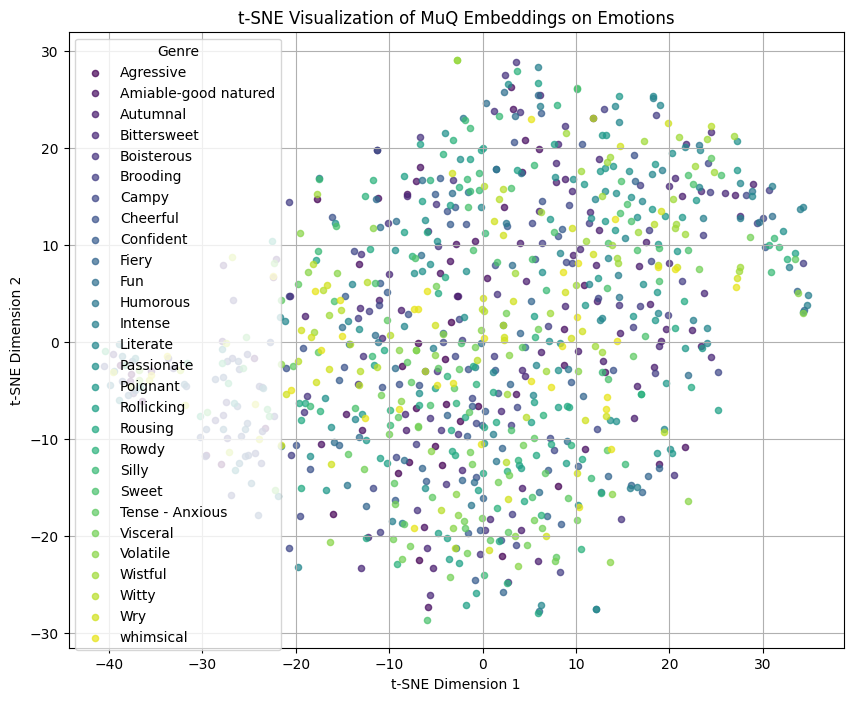

In [10]:
from tsne_vis import load_embeddings
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np



embeddings , genres , filenames = load_embeddings()
X_2d = TSNE(n_components=2, random_state=42).fit_transform(embeddings)
print("Loaded embeddings shape:", embeddings.shape)
print("t-SNE result shape:", X_2d.shape)
plt.figure(figsize=(10, 8))
# Obtenir la liste unique des genres
unique_genres = np.unique(genres)
n_classes = len(unique_genres)
# Couleurs : utiliser un colormap qui a assez de couleurs pour tous les genres
cmap = plt.get_cmap("viridis")
colors = [cmap(i / n_classes) for i in range(n_classes)]
class_to_color = {cls: colors[i] for i, cls in enumerate(unique_genres)}
# Plot genre par genre
for genre in unique_genres:
    idx = genres == genre
    plt.scatter(X_2d[idx, 0], X_2d[idx, 1], label=genre, color=class_to_color[genre], alpha=0.7, s=20)
plt.title("t-SNE Visualization of MuQ Embeddings on Emotions")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Genre")
plt.grid(True)
# Sauvegarde du graphique
plt.savefig("tsne_muQ_embeddings_MIREX.png", dpi=300)
print("✅ t-SNE plot saved as tsne_muQ_embeddings_FMA.png")